In [ ]:
Practical No:11
Roll no: 46
Title:Analyzing Sales Performance by Region in a Retail Company 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

print(df.head())

   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   Sout

In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (9994, 21)

Column names:
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  S

In [4]:
# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing region, sales, or profit
df = df.dropna(subset=["Region", "Sales", "Profit"])

# Convert order date to date format
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

print("Missing values:")
print(df[["Region", "Sales", "Profit"]].isnull().sum())

print("Cleaned dataset shape:", df.shape)

Missing values:
Region    0
Sales     0
Profit    0
dtype: int64
Cleaned dataset shape: (9994, 21)


In [5]:
region_sales = df.groupby("Region")["Sales"].sum()
region_profit = df.groupby("Region")["Profit"].sum()

print("Total Sales by Region:")
print(region_sales)

print("\nTotal Profit by Region:")
print(region_profit)

Total Sales by Region:
Region
Central    501239.8908
East       678781.2400
South      391721.9050
West       725457.8245
Name: Sales, dtype: float64

Total Profit by Region:
Region
Central     39706.3625
East        91522.7800
South       46749.4303
West       108418.4489
Name: Profit, dtype: float64


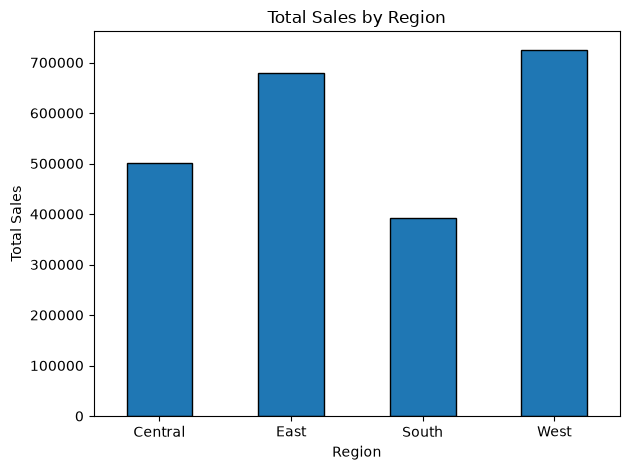

In [6]:
region_sales.plot(kind="bar", edgecolor="black")

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

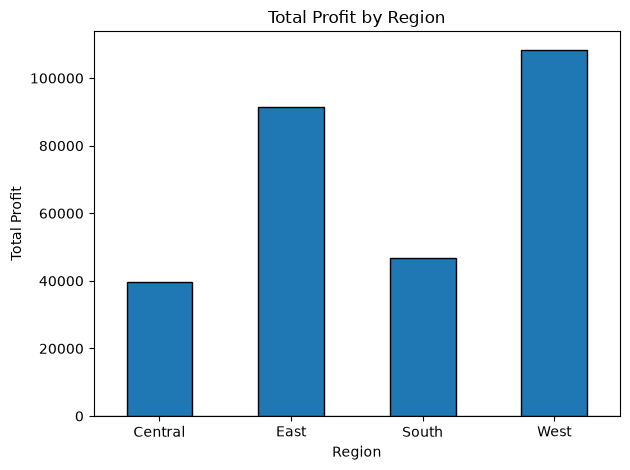

In [7]:
region_profit.plot(kind="bar", edgecolor="black")

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.axhline(0, linewidth=1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Category    Furniture  Office Supplies  Technology
Region                                            
Central   163797.1638       167026.415  170416.312
East      208291.2040       205516.055  264973.981
South     117298.6840       125651.313  148771.908
West      252612.7435       220853.249  251991.832


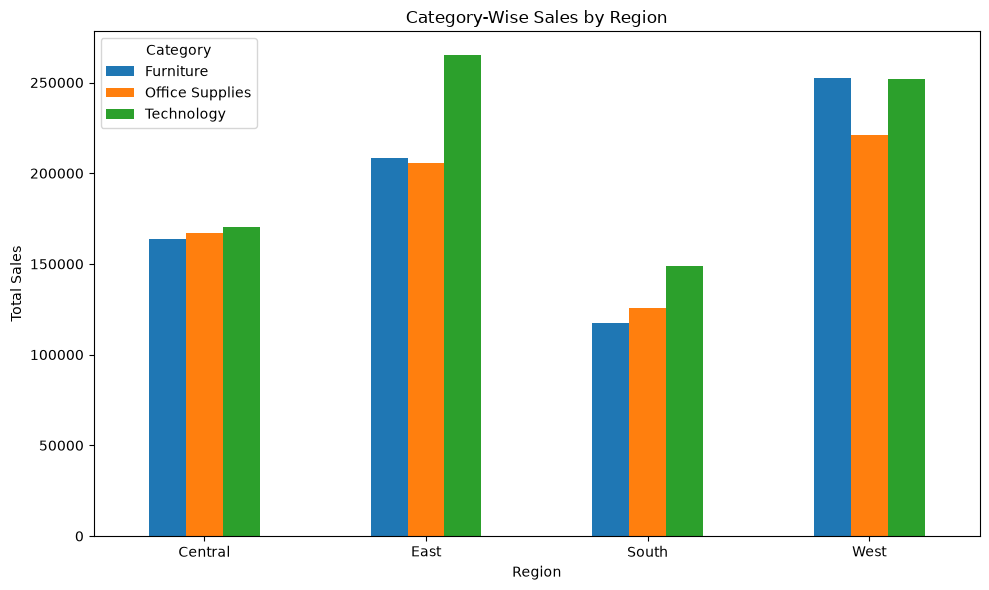

In [8]:
category_sales = df.pivot_table(
    index="Region",
    columns="Category",
    values="Sales",
    aggfunc="sum"
)

print(category_sales)

category_sales.plot(kind="bar", figsize=(10, 6))

plt.title("Category-Wise Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

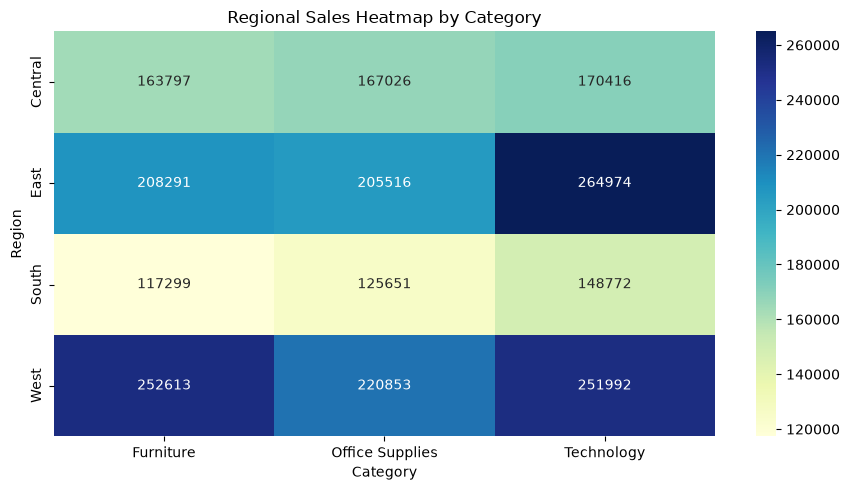

In [9]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    category_sales,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Regional Sales Heatmap by Category")
plt.tight_layout()
plt.show()

In [10]:
best_sales_region = region_sales.idxmax()
best_profit_region = region_profit.idxmax()

print("Region with highest sales:", best_sales_region)
print("Highest sales:", round(region_sales.max(), 2))

print("\nRegion with highest profit:", best_profit_region)
print("Highest profit:", round(region_profit.max(), 2))

Region with highest sales: West
Highest sales: 725457.82

Region with highest profit: West
Highest profit: 108418.45


In [11]:
summary = pd.DataFrame({
    "Total Sales": region_sales,
    "Total Profit": region_profit
})

summary.to_csv("Regional_Sales_Analysis.csv")

print("Analysis saved successfully!")
print(summary)

Analysis saved successfully!
         Total Sales  Total Profit
Region                            
Central  501239.8908    39706.3625
East     678781.2400    91522.7800
South    391721.9050    46749.4303
West     725457.8245   108418.4489
